# 739. Daily Temperatures
**Difficulty:** 🟡 Medium · **Topic:** Stack · **Pattern:** [Monotonic Stack](README.md) · **LeetCode:** https://leetcode.com/problems/daily-temperatures/

## 💡 Concepts

**Core concept(s):** **Monotonic decreasing stack of indices** — the "next greater element" problem in disguise.

**Why it applies here:**
- For every day we need the **next day to the right that is warmer**: the *next greater element*.
- A day that has not found its warmer day yet is **waiting**. The days still waiting always have temperatures that go **down (or stay level)** from older to newer — a warmer day would already have ended the wait of every cooler day before it.
- So the waiting days form a **decreasing stack**. When a warmer day arrives, it ends the wait of the days on top, newest first.
- The answer is a **distance in days** (`i - j`), so the stack must hold **indices**, not temperatures.

**Key intuition:**
- Walk the days left to right.
- Today pops every waiting day that is cooler than today and writes `today - that_day` as its answer.
- Then today joins the stack and waits for its own warmer day.
- Days still on the stack at the end never get a warmer day: their answer stays `0`.

---

### 📚 What is a Stack?
- A **stack** is a pile: you add (**push**) and remove (**pop**) only at the **top**.
- Last in, first out: the item pushed most recently is the first one popped.
- **Key operations:** push, pop, peek at the top — all **O(1)**.
- **In Python:** a plain `list` — `append` pushes, `pop()` pops, `stack[-1]` peeks.

### 📚 What is a Monotonic Stack?
- A **monotonic stack** is an ordinary stack with one rule: the values it holds stay **sorted** from bottom to top (always decreasing, or always increasing).
- Before pushing a new item, you **pop every item that would break the order**. Those pops are the useful part: the new item is the *answer* for each item it pops (its "next greater" or "next smaller" element).
- It usually stores **indices**, not values: the value is `arr[i]`, and the index gives distances and widths (`i - j`).
- **Complexity:** each index is pushed once and popped at most once, so a full pass is **O(n)** even though there is a `while` loop inside the `for` loop.
- **In Python:** a `list` used as a stack, plus the `while stack and <order broken>: stack.pop()` loop.

### 📚 What is Amortized Analysis?
- Some loops look expensive one step at a time but are cheap **in total**.
- **Amortized** cost = total work divided by the number of steps.
- Here: one step of the outer `for` may pop many items, but every item can be popped **only once** in the whole run, so all the pops together cost at most `n`.
- Result: `n` pushes + at most `n` pops = **O(n)** overall, i.e. **O(1) amortized** per element.

---

**Prerequisite knowledge:**
- Python lists used as stacks (see the [Stack Simulation](../01_Stack_Simulation/README.md) pattern).

## 📝 Problem

Given an array `temperatures` of daily temperatures, return an array `answer` where `answer[i]` is the **number of days you have to wait after day `i` to get a warmer temperature**. If no future day is warmer, `answer[i] = 0`.

**Example 1**
```
temperatures = [73, 74, 75, 71, 69, 72, 76, 73]
answer       = [ 1,  1,  4,  2,  1,  1,  0,  0]
```
Day 2 (75) waits 4 days for 76 on day 6. Days 6 and 7 never see anything warmer.

**Example 2:** `[30, 40, 50, 60]` → `[1, 1, 1, 0]`

**Example 3:** `[30, 60, 90]` → `[1, 1, 0]`

**Constraints:** `1 <= temperatures.length <= 10^5`, `30 <= temperatures[i] <= 100`.

> Three approaches: a brute-force scan to the right (`O(n²)`), a right-to-left pass that jumps along answers it already knows (`O(n)` amortized, `O(1)` extra space), and the monotonic stack (`O(n)`, the pattern template).

In [1]:
from typing import List

### Approach 1 — Brute Force: scan right from every day

**Idea:**
1. For each day `i`, look at days `i+1, i+2, ...` one by one.
2. Stop at the first day `j` that is warmer and record `j - i`.
3. If you reach the end without finding one, leave `0`.

**Time complexity:** `O(n²)` — when no warmer day exists (or it is far away), each day scans the whole rest of the array: `n + (n-1) + ... ≈ n²/2` comparisons.

**Space complexity:** `O(1)` extra — only loop indices (the output array aside).

In [2]:
def daily_temperatures_brute(temperatures: List[int]) -> List[int]:
    n = len(temperatures)
    res = [0] * n
    for i in range(n):
        for j in range(i + 1, n):                  # look further and further right
            if temperatures[j] > temperatures[i]:  # first warmer day found
                res[i] = j - i                     # the answer is a distance in days
                break                              # later days can't be "next"
    return res

### Approach 2 — Right to left, jump along known answers

**Idea:**
1. Fill the answers from the **last** day to the first, so every answer to the right of `i` is already known.
2. Start at `j = i + 1`. If day `j` is not warmer than day `i`, nothing between `j` and *day `j`'s own warmer day* can be warmer either (they are all `<= temperatures[j] <= temperatures[i]`), so **jump** straight to `j + res[j]`.
3. If `res[j] == 0`, nothing to the right is warmer than day `j`. Since `temperatures[j] <= temperatures[i]`, nothing is warmer than day `i` either: stop with `0`.

**Time complexity:** `O(n)` amortized — the jumps follow the same "next warmer" links a monotonic stack would pop; each link is skipped over by at most one later day, so all the jumps together are `O(n)`.

**Space complexity:** `O(1)` extra — no stack; it reuses the output array as its memory.

In [3]:
def daily_temperatures_jump(temperatures: List[int]) -> List[int]:
    n = len(temperatures)
    res = [0] * n
    for i in range(n - 2, -1, -1):                 # right to left: res[i+1:] is already final
        j = i + 1
        while j < n and temperatures[j] <= temperatures[i]:
            # day j is not warmer; every day before j's warmer day is <= temps[j], so skip them all
            j = j + res[j] if res[j] else n        # res[j] == 0: nothing to the right beats day j, nor day i
        res[i] = j - i if j < n else 0
    return res

### Approach 3 — Monotonic Decreasing Stack (optimal · pattern template)

**Idea:** the [Monotonic Stack](README.md) template with a "pop while the top is cooler than today" rule.
1. Keep a stack of **indices** of days still waiting for a warmer day. Their temperatures never increase from bottom to top.
2. For each day `i`: while the top day is **cooler** than today, pop it (`j`) and set `res[j] = i - j` — today is its next warmer day.
3. Push `i`: today now waits for its own warmer day.
4. Indices left on the stack at the end have no warmer day; their `0` stays.

**Time complexity:** `O(n)` — each index is pushed once and popped at most once, so the inner `while` runs at most `n` times in total.

**Space complexity:** `O(n)` — the stack can hold every index (e.g. temperatures that never rise).

> Same `O(n)` time as Approach 2. The stack is the interview target: it is the reusable next-greater template, and its `O(n)` proof is one sentence ("each index is pushed and popped once"). Approach 2 saves the stack's memory but its amortized bound is harder to argue.

In [4]:
def daily_temperatures_stack(temperatures: List[int]) -> List[int]:
    res = [0] * len(temperatures)
    stack = []                                     # indices of days still waiting; temps never rise bottom -> top
    for i, t in enumerate(temperatures):
        while stack and temperatures[stack[-1]] < t:   # today is warmer than the day on top
            j = stack.pop()                        # day j's wait is over...
            res[j] = i - j                         # ...after i - j days (why we store INDICES)
        stack.append(i)                            # today waits for its own warmer day
    return res                                     # days left on the stack keep 0

In [5]:
# Correctness check
import random

tests = [
    ([73, 74, 75, 71, 69, 72, 76, 73], [1, 1, 4, 2, 1, 1, 0, 0]),  # LeetCode example 1
    ([30, 40, 50, 60],                 [1, 1, 1, 0]),              # example 2: always rising
    ([30, 60, 90],                     [1, 1, 0]),                 # example 3
    ([90, 80, 70, 60],                 [0, 0, 0, 0]),              # always falling: nobody ever pops
    ([50, 50, 50, 51],                 [3, 2, 1, 0]),              # equal is NOT warmer
    ([55],                             [0]),                       # single day
]
for temps, exp in tests:
    a = daily_temperatures_brute(temps)
    b = daily_temperatures_jump(temps)
    c = daily_temperatures_stack(temps)
    print(f"{str(temps):34} -> {c}")
    assert a == b == c == exp, f"mismatch on {temps}: brute={a} jump={b} stack={c}"

# Randomised cross-check: all three approaches must agree
rng = random.Random(739)
for _ in range(500):
    temps = [rng.randint(30, 40) for _ in range(rng.randint(1, 60))]   # narrow range -> many ties
    assert daily_temperatures_brute(temps) == daily_temperatures_jump(temps) == daily_temperatures_stack(temps), temps
print("500 random inputs: all three approaches agree")

print("\nAll tests passed")

[73, 74, 75, 71, 69, 72, 76, 73]   -> [1, 1, 4, 2, 1, 1, 0, 0]
[30, 40, 50, 60]                   -> [1, 1, 1, 0]
[30, 60, 90]                       -> [1, 1, 0]
[90, 80, 70, 60]                   -> [0, 0, 0, 0]
[50, 50, 50, 51]                   -> [3, 2, 1, 0]
[55]                               -> [0]
500 random inputs: all three approaches agree

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. We time each approach on inputs of growing size `n` and read the **doubling ratio** — how much the runtime grows when `n` doubles.

| Theoretical | Ratio when `n` → `2n` |
|-------------|-----------------------|
| `O(n)`      | ≈ **2×** |
| `O(n²)`     | ≈ **4×** |

**Worst-case input:** `n - 1` days at 50° followed by one day at 51°. Every day's first warmer day is the **last** one, so the brute force scans to the end from every day (no early `break`), while the stack holds all `n - 1` waiting days and pops them all on the last day — the most popping the stack ever does. Approach 2 takes two jumps per day.


brute O(n^2)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     1000 |      13.26 |           n/a


     2000 |      54.39 |         4.10x


     4000 |     217.88 |         4.01x


     8000 |     871.21 |         4.00x

jump O(n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     1000 |       0.13 |           n/a
     2000 |       0.25 |         1.93x
     4000 |       0.54 |         2.17x
     8000 |       1.05 |         1.95x

stack O(n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     1000 |       0.12 |           n/a
     2000 |       0.26 |         2.20x
     4000 |       0.45 |         1.73x
     8000 |       0.89 |         1.98x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


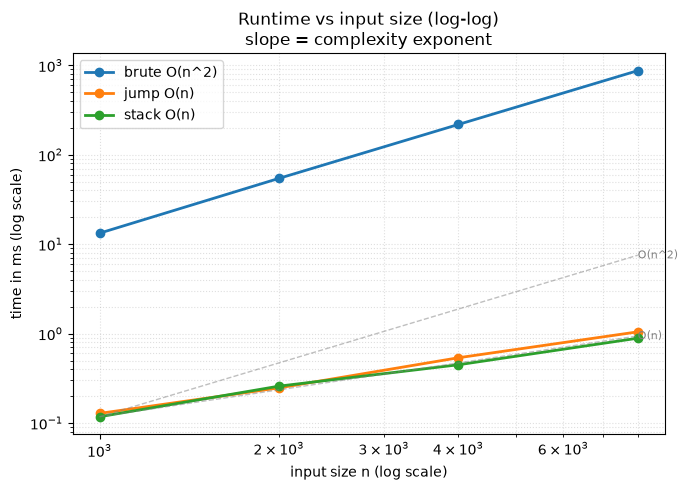

{'brute O(n^2)': [13.260332983918488,
  54.385207942686975,
  217.88341598585248,
  871.2092080386356],
 'jump O(n)': [0.12808304745703936,
  0.2471250481903553,
  0.5366250406950712,
  1.0456659365445375],
 'stack O(n)': [0.11754198931157589,
  0.2584579633548856,
  0.4479580093175173,
  0.887917005456984]}

In [6]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark

def make_worst_case(n):
    return ([50] * (n - 1) + [51],)        # the only warmer day is the very last one
solutions = {
    "brute O(n^2)": daily_temperatures_brute,
    "jump O(n)": daily_temperatures_jump,
    "stack O(n)": daily_temperatures_stack,
}
sizes = [1000, 2000, 4000, 8000]

benchmark(solutions, make_worst_case, sizes, repeats=3, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [Monotonic Stack](README.md) — the canonical use: a decreasing stack of day indices; each warmer day pops the cooler days it ends the wait for and writes `i - j`.
- **Next greater element → monotonic decreasing stack.** "Next warmer", "next taller", "next larger to the right" all use the same loop; "next smaller" flips `<` to `>` (an increasing stack).
- **Store indices, not values.** The answer is a distance; the value is always `temperatures[j]`. A stack of values loses the position the moment it is pushed.
- **Amortized O(n):** a `while` inside a `for` is still linear when every element is pushed once and popped at most once.
- **Signal:** "how many days until", "next greater / warmer / taller element", "for each element, the first element to its right that ...".
- **Related problems:** Next Greater Element I / II, Online Stock Span, Car Fleet, Largest Rectangle in Histogram, Remove K Digits.
- **Common pitfalls:**
  1. Popping on `<=` instead of `<`: an equal temperature is **not** warmer (`[50, 50, 51]` → `[2, 1, 0]`).
  2. Pushing temperatures instead of indices, then having no way to compute `i - j`.
  3. Forgetting that leftover indices mean "no warmer day" — they must stay `0`, which `[0] * n` handles for free.